In [1]:
import numpy as np
import scanpy as sc
import rapids_singlecell as rsc
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
from tqdm import tqdm
from pprint import pprint

sc.set_figure_params(frameon=False, dpi=80, fontsize=12)

from scatlastb_utils.io import read_anndata, write_zarr
from scatlastb_utils.pipeline.misc import dask_compute

/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cuda module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.driver module instead.
/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jup

# Read data

## Read hyperparameters

In [2]:
hyperparams = pd.read_table('data/pipeline/feature_selection/HICA/clustering/input_files.tsv')

In [3]:
hyperparams = hyperparams.query('dataset == "global"').copy()
hyperparams['integration'] = hyperparams['file_id'].str.split('--').str[1]
hyperparams['hyperparams'] = hyperparams['file_path'].str.split('var_mask~').str[1]

In [4]:
hyperparams

,dataset,file_id,file_path,integration,hyperparams
15,global,integration:preprocessing:All--integration=429...,data/pipeline/feature_selection/HICA/integrati...,integration=429013bad9,extra_hvgs--batch_key=library_id--n_top_genes=...
16,global,integration:preprocessing:All--integration=b6d...,data/pipeline/feature_selection/HICA/integrati...,integration=b6db15edb2,highly_variable/method~unintegrated--hyperpara...
17,global,integration:preprocessing:All--integration=e99...,data/pipeline/feature_selection/HICA/integrati...,integration=e99de4b0f4,extra_hvgs--batch_key=library_id--n_top_genes=...
18,global,integration:preprocessing:All--integration=8db...,data/pipeline/feature_selection/HICA/integrati...,integration=8db25de1ea,highly_variable/method~harmony_pytorch--hyperp...
19,global,integration:preprocessing:All--integration=d66...,data/pipeline/feature_selection/HICA/integrati...,integration=d66e3b5375,extra_hvgs--batch_key=library_id--n_top_genes=...
20,global,integration:preprocessing:All--integration=511...,data/pipeline/feature_selection/HICA/integrati...,integration=51114673bc,highly_variable/method~scvi--hyperparams~67687...
21,global,integration:preprocessing:All--integration=45a...,data/pipeline/feature_selection/HICA/integrati...,integration=45a6d11dd6,extra_hvgs--batch_key=library_id--n_top_genes=...
22,global,integration:preprocessing:All--integration=f4a...,data/pipeline/feature_selection/HICA/integrati...,integration=f4ab30fa45,highly_variable/method~drvi--hyperparams~4a9ca...


## Read all cells

In [5]:
file_path = 'data/pipeline/feature_selection/HICA/majority_voting/dataset~global/file_id~collect:global.zarr'

In [6]:
ll {file_path}

total 32
lrwxrwxrwx   1 michaela.mueller   141 Oct 28 01:17 layers -> '../../../integration/prepare/dataset~global/file_id~preprocessing:All/var_mask~extra_hvgs--batch_key=library_id--n_top_genes=3000.zarr/layers'/
drwxrwxr-x 137 michaela.mueller 20480 Oct 28 01:17 obs/
lrwxrwxrwx   1 michaela.mueller    41 Oct 28 01:17 obsm -> ../../../collect/dataset~global.zarr/obsm/
lrwxrwxrwx   1 michaela.mueller    41 Oct 28 01:17 obsp -> ../../../collect/dataset~global.zarr/obsp/
drwxrwxr-x   2 michaela.mueller  4096 Oct 27 08:41 subset_mask/
lrwxrwxrwx   1 michaela.mueller    40 Oct 28 01:17 uns -> ../../../collect/dataset~global.zarr/uns/
lrwxrwxrwx   1 michaela.mueller   138 Oct 28 01:17 var -> '../../../integration/prepare/dataset~global/file_id~preprocessing:All/var_mask~extra_hvgs--batch_key=library_id--n_top_genes=3000.zarr/var'/
lrwxrwxrwx   1 michaela.mueller    48 Oct 28 01:17 varm -> ../../../merge/dataset~predict_lineage.zarr/varm/
lrwxrwxrwx   1 michaela.mueller    48 Oct 28 01:17 v

In [7]:
adata = read_anndata(
    file_path,
    dask=True,
    backed=True,
    X='layers/normcounts',
    layers='layers',
    obs='obs',
    var='var',
    obsm='obsm',
    dask_slots=['X', 'layers', 'obsp', 'obsm'],
    uns='uns',
    # select_keys=
)

dask: True, backed: True
chunks: (200000, -1)
Read slot "layers/normcounts", store as "X"...
Read layers/normcounts as backed sparse dask array...
Read slot "layers", store as "layers"...


Read layers slots as_dask=True: 100%|██████████| 2/2 [00:00<00:00, 81.99it/s]

Read slot "obs", store as "obs"...


Read slot "var", store as "var"...
Read slot "obsm", store as "obsm"...


Read obsm slots as_dask=True: 100%|██████████| 28/28 [00:46<00:00,  1.65s/it]

Read slot "uns", store as "uns"...



Read uns slots as_dask=False: 100%|██████████| 160/160 [00:03<00:00, 50.88it/s]

shape: (5239652, 36601)


# Export data

In [8]:
output_dir = 'data/output/export'
file_name = 'hica_global.zarr'

In [24]:
%%time
write_zarr(adata, f'{output_dir}/{file_name}')

CPU times: user 6min 9s, sys: 2min 1s, total: 8min 11s
Wall time: 10min 14s


In [25]:
!du -hs {output_dir}/{file_name}

74G	data/output/export/hica_global.zarr


In [26]:
!du -hd1 {output_dir}/{file_name} | sort -h

12K	data/output/export/hica_global.zarr/obsp
12K	data/output/export/hica_global.zarr/varm
12K	data/output/export/hica_global.zarr/varp
760K	data/output/export/hica_global.zarr/var
5.5M	data/output/export/hica_global.zarr/uns
582M	data/output/export/hica_global.zarr/obs
16G	data/output/export/hica_global.zarr/obsm
23G	data/output/export/hica_global.zarr/X
36G	data/output/export/hica_global.zarr/layers
75G	data/output/export/hica_global.zarr


In [27]:
ll {output_dir}

total 40398828
-rw-r--r--  1 michaela.mueller  3811286419 Nov 10 03:59 hica_cxg_pseudobulk.h5ad
-rw-r--r--  1 michaela.mueller        3390 Nov 12 07:24 hica_global_hyperparams.csv
drwxr-xr-x 11 michaela.mueller        4096 Nov 12 07:39 hica_global.zarr/
-rw-rw-r--  1 michaela.mueller 37557070267 Nov 10 05:08 hica_global.zarr.tar.lz4


In [28]:
%%time
!cd {output_dir} && tar cf - {file_name} | lz4 -f -9 - {file_name}.tar.lz4

Compressed 80828835840 bytes into 71816131638 bytes ==> 88.85%                 


In [29]:
!echo rclone copy -P {output_dir}/{file_name}.tar.lz4 onedrive:HICA/

rclone copy -P data/output/export/hica_global.zarr.tar.lz4 onedrive:HICA/


In [9]:
hyperparams.to_csv(f'{output_dir}/hica_global_hyperparams.csv', index=False, sep=';')

# Plot UMAPs

In [10]:
pprint(
    hyperparams.set_index('integration')['hyperparams'].to_dict()
)

{'integration=429013bad9': 'extra_hvgs--batch_key=library_id--n_top_genes=3000/method~unintegrated--hyperparams~None--label~None--output_type~embed.zarr',
 'integration=45a6d11dd6': 'extra_hvgs--batch_key=library_id--n_top_genes=3000/method~drvi--hyperparams~4a9ca95bc9--label~None--output_type~embed.zarr',
 'integration=51114673bc': 'highly_variable/method~scvi--hyperparams~676871383b--label~None--output_type~embed.zarr',
 'integration=8db25de1ea': 'highly_variable/method~harmony_pytorch--hyperparams~9c178fa727--label~None--output_type~embed.zarr',
 'integration=b6db15edb2': 'highly_variable/method~unintegrated--hyperparams~None--label~None--output_type~embed.zarr',
 'integration=d66e3b5375': 'extra_hvgs--batch_key=library_id--n_top_genes=3000/method~scvi--hyperparams~676871383b--label~None--output_type~embed.zarr',
 'integration=e99de4b0f4': 'extra_hvgs--batch_key=library_id--n_top_genes=3000/method~harmony_pytorch--hyperparams~9c178fa727--label~None--output_type~embed.zarr',
 'integr

In [11]:
integration = '3517ff5245'

In [12]:
adata.uns[f'integration--label_transfer:clustering:integration:preprocessing:All--integration={integration}']['hyperparams']

{'dispersion': 'gene-batch',
 'dropout_rate': 0.2,
 'early_stopping': True,
 'max_epochs': 50,
 'n_hidden': 128,
 'n_latent': 30,
 'n_layers': 2,
 'use_observed_lib_size': True}

In [13]:
adata.obsm[f'X_umap--label_transfer:clustering:integration:preprocessing:All--integration={integration}'] = \
    adata.obsm[f'X_umap--label_transfer:clustering:integration:preprocessing:All--integration={integration}'].compute()

In [14]:
colors =[
    'assay',
    'celltypist_Healthy_COVID19_PBMC:majority_voting',
    'celltypist_COVID19_HumanChallenge_Blood:majority_voting',
    'lineage',
    'sex',
    'development_stage_ontology_term_id',
    'study',
    'disease',
]

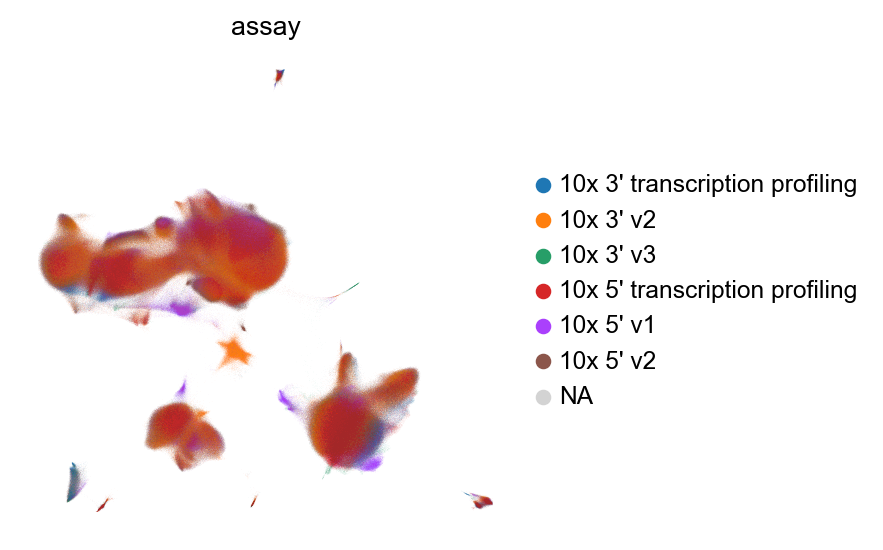

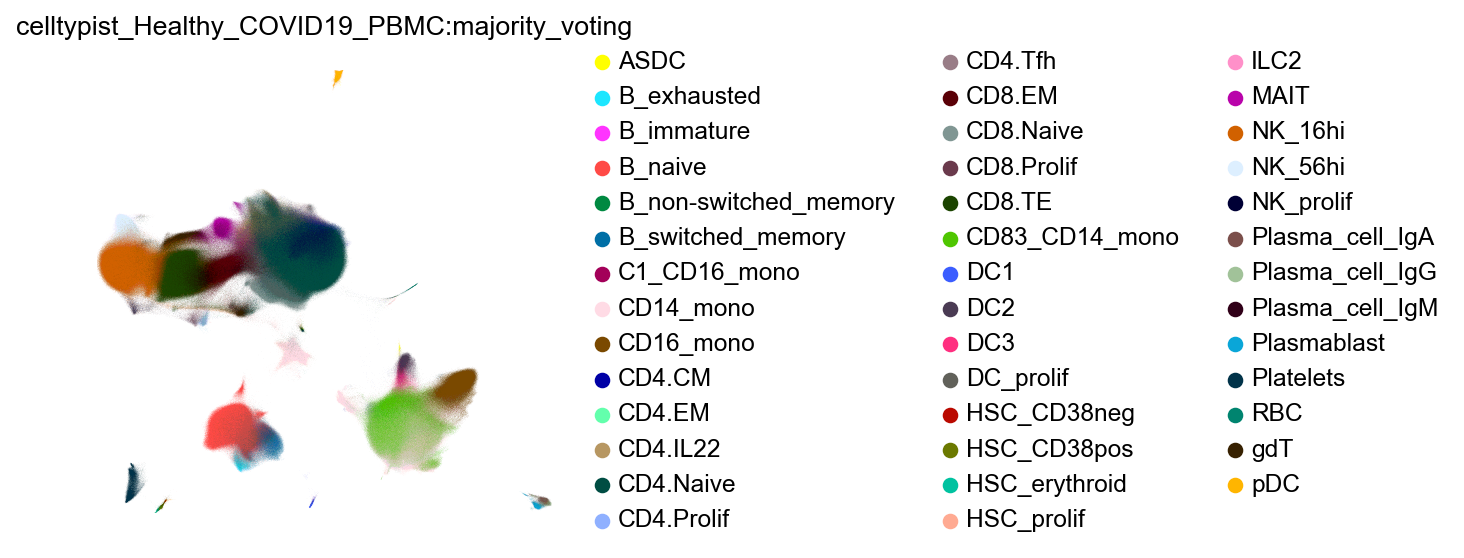

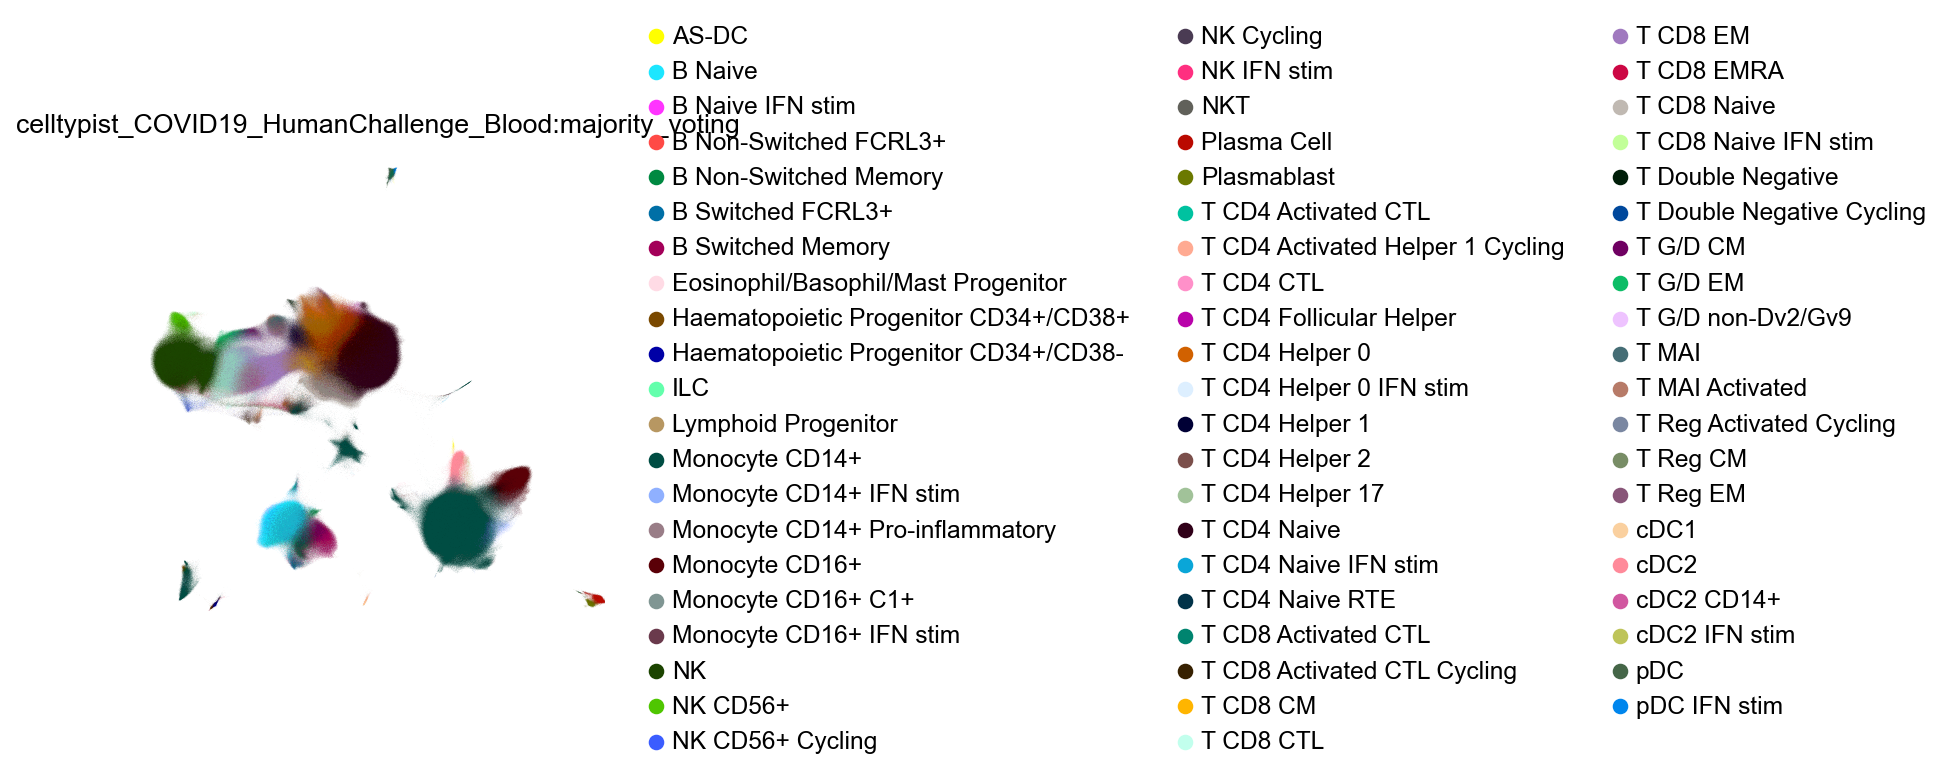

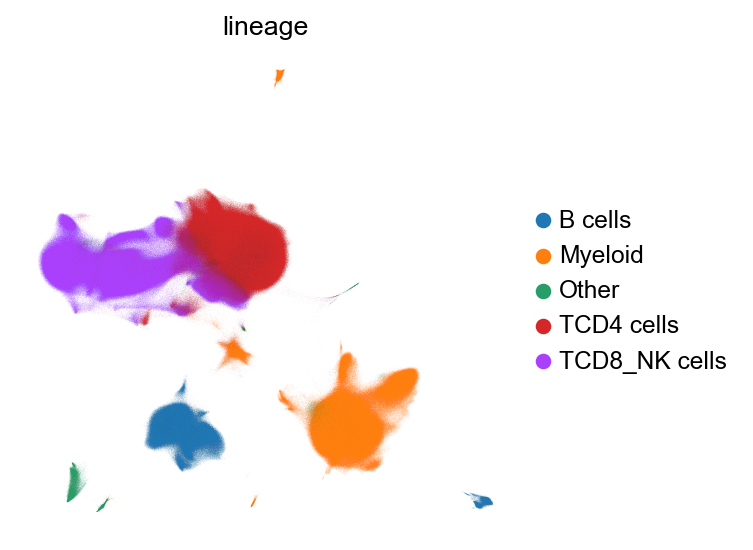

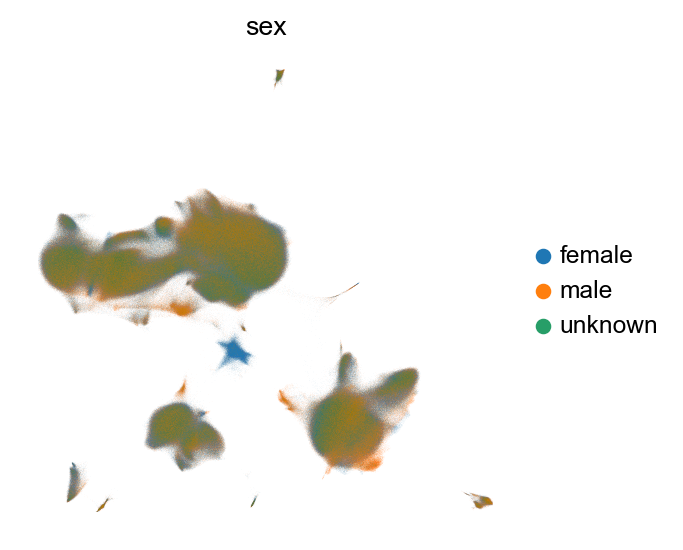

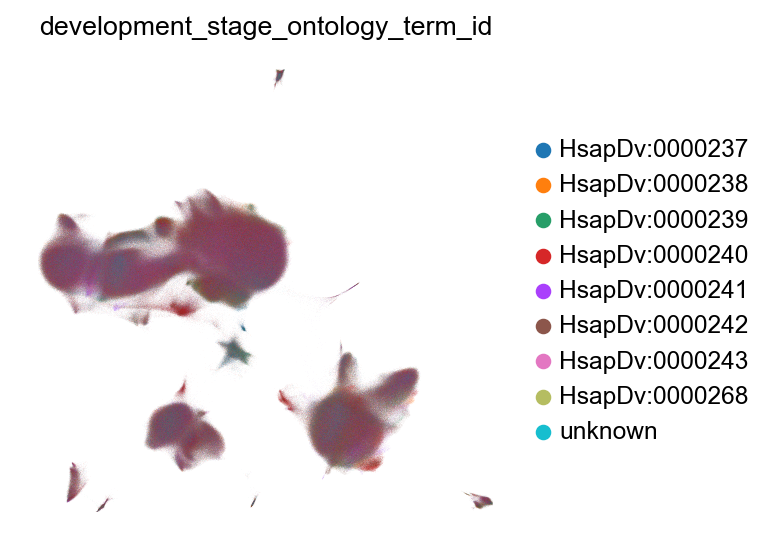

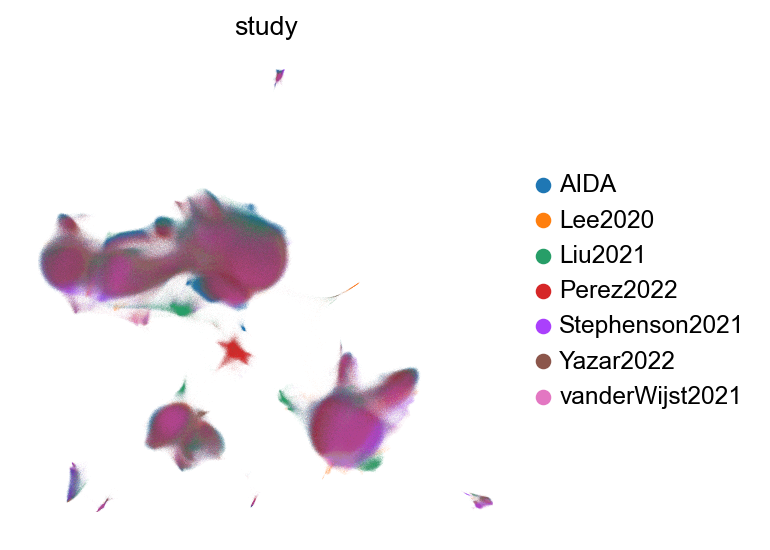

In [ ]:
%%time
for color in colors:
    sc.pl.embedding(
        adata,
        basis=f'X_umap--label_transfer:clustering:integration:preprocessing:All--integration={integration}',
        color=color,
        ncols=1,
    )

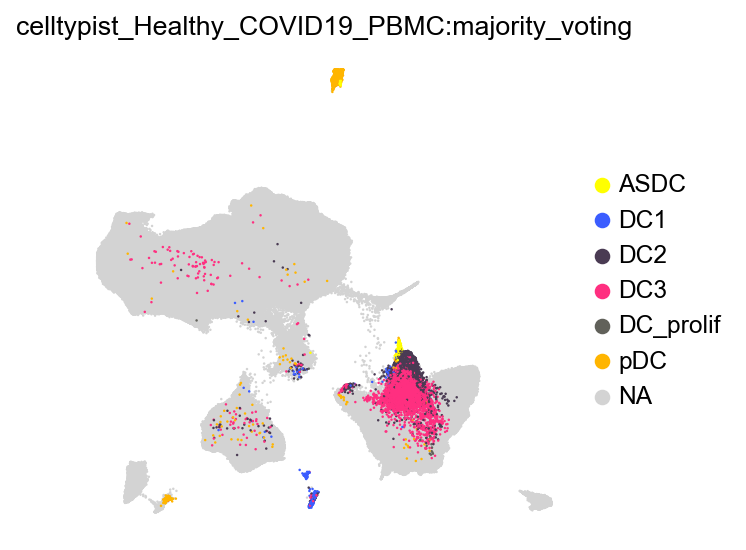

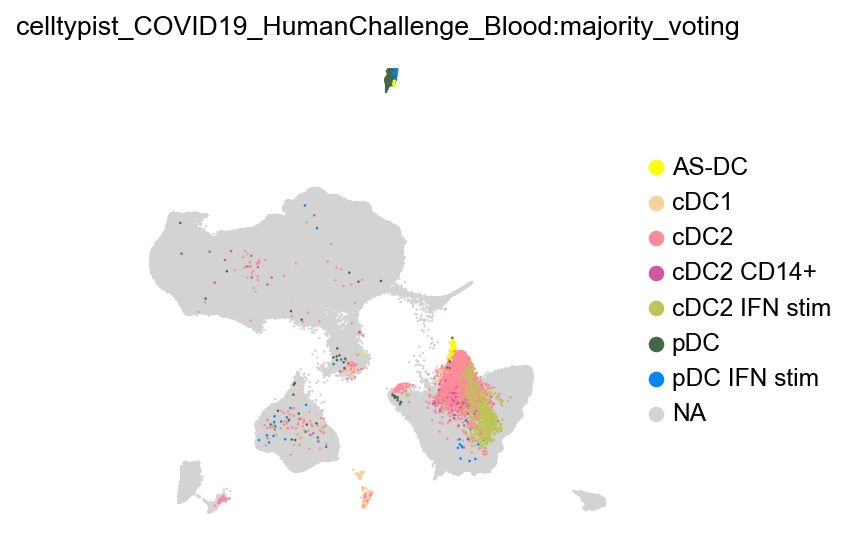

In [16]:
for color in [
    'celltypist_Healthy_COVID19_PBMC:majority_voting',
    'celltypist_COVID19_HumanChallenge_Blood:majority_voting',
]:
    sc.pl.embedding(
        adata,
        basis=f'X_umap--label_transfer:clustering:integration:preprocessing:All--integration={integration}',
        color=color,
        groups=[c for c in adata.obs[color].unique() if 'DC' in c],
        ncols=1,
        size=5,
    )

## Subset to DC

In [17]:
adata.obs['celltypist_Healthy_COVID19_PBMC:majority_voting'].str.contains('DC')

predict_lineage-0          False
predict_lineage-1          False
predict_lineage-2          False
predict_lineage-3          False
predict_lineage-4          False
                           ...  
predict_lineage-5239647    False
predict_lineage-5239648    False
predict_lineage-5239649    False
predict_lineage-5239650    False
predict_lineage-5239651    False
Name: celltypist_Healthy_COVID19_PBMC:majority_voting, Length: 5239652, dtype: bool

In [18]:
adata.obs['DC'] = adata.obs['celltypist_Healthy_COVID19_PBMC:majority_voting'].str.contains('DC')
adata.obs['DC'] = adata.obs['DC'] | adata.obs['celltypist_COVID19_HumanChallenge_Blood:majority_voting'].str.contains('DC')

In [19]:
adata_dc = adata[adata.obs['DC']].copy()

In [20]:
use_rep = f'X_emb--label_transfer:clustering:integration:preprocessing:All--integration={integration}'
adata_dc.obsm[use_rep] = adata_dc.obsm[use_rep].compute()

In [21]:
rsc.pp.neighbors(
    adata_dc,
    use_rep=use_rep,
)

In [22]:
rsc.tl.umap(adata_dc)

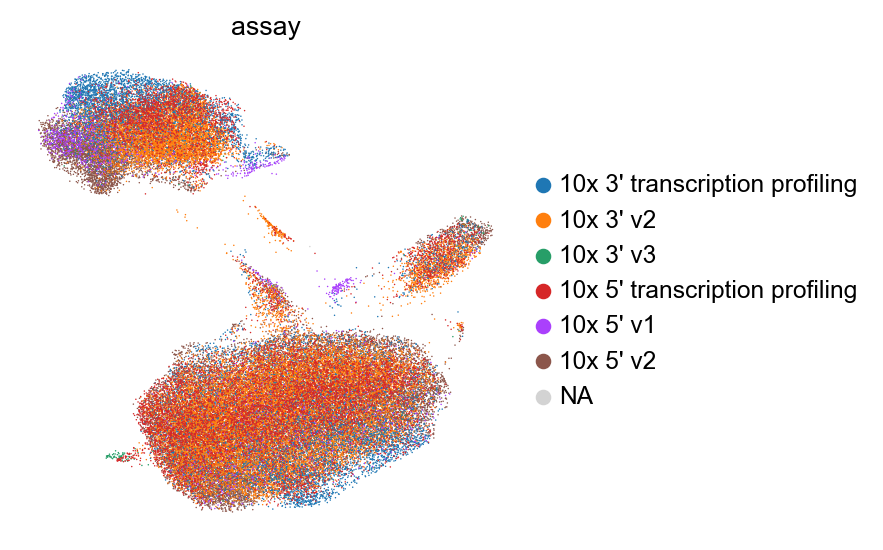

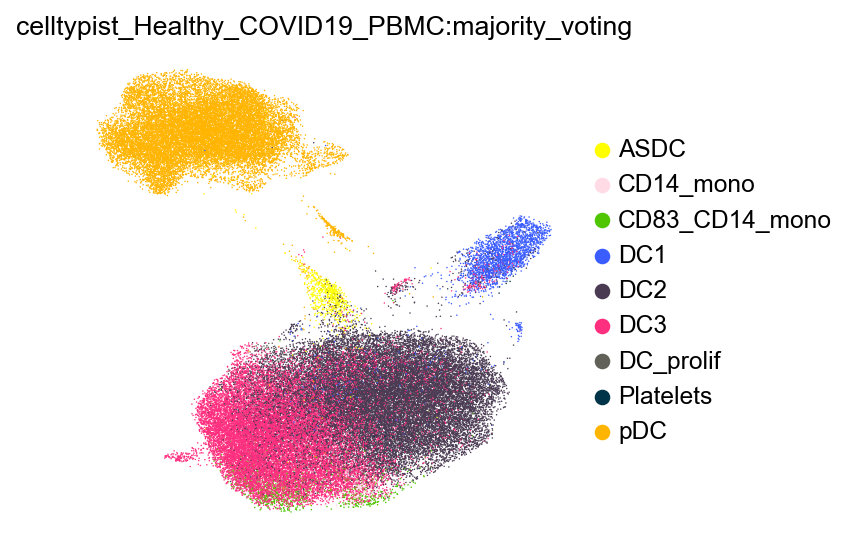

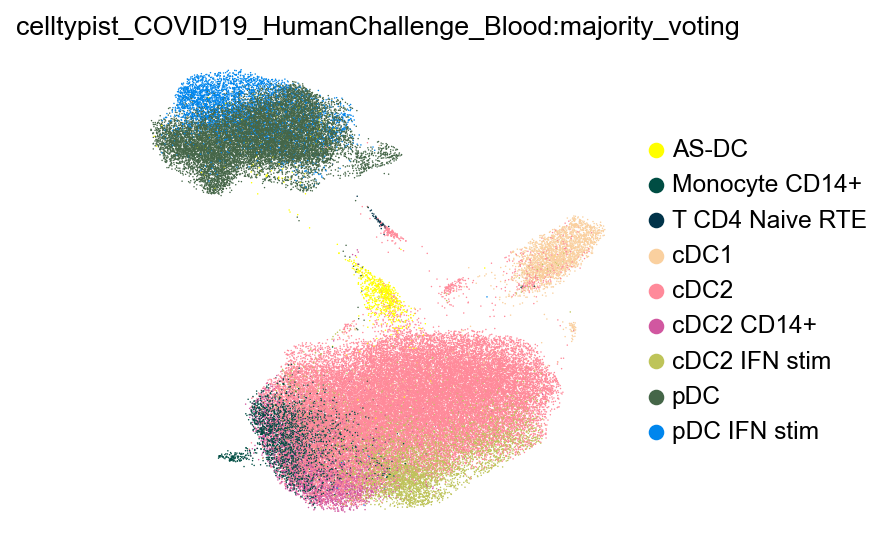

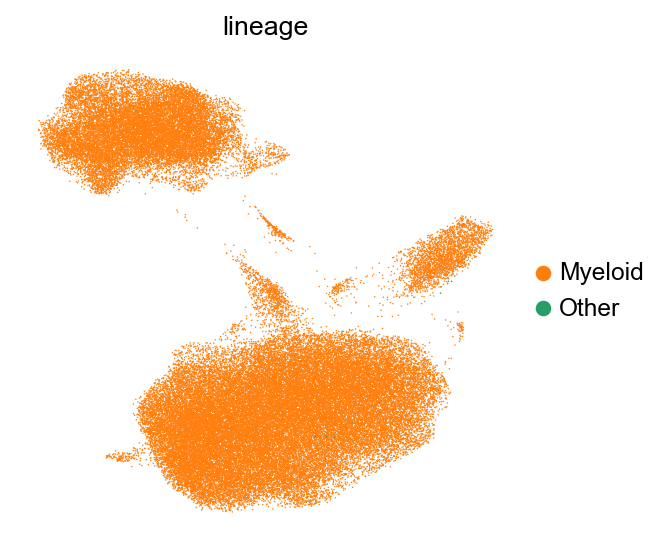

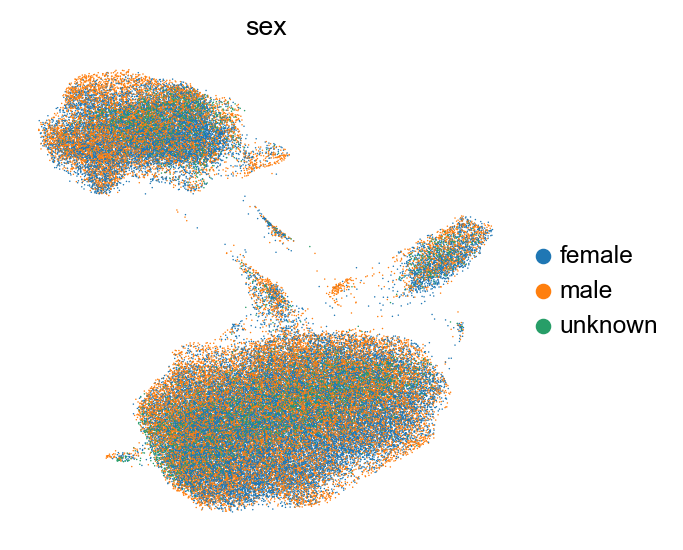

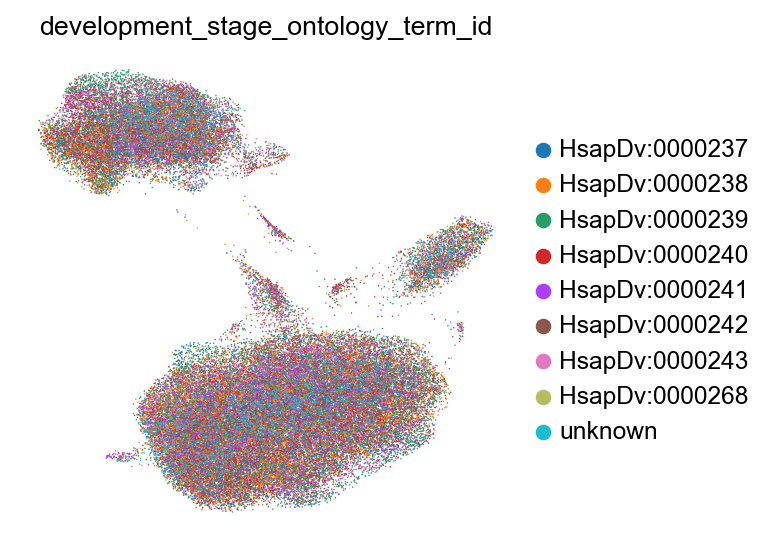

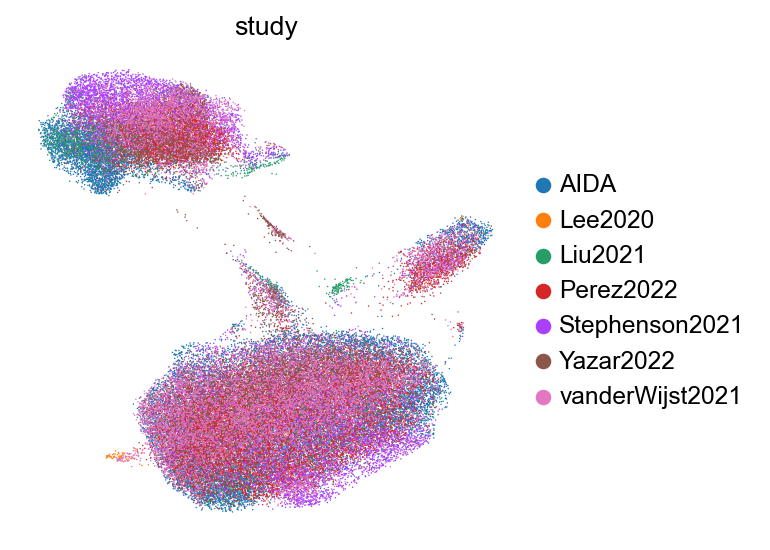

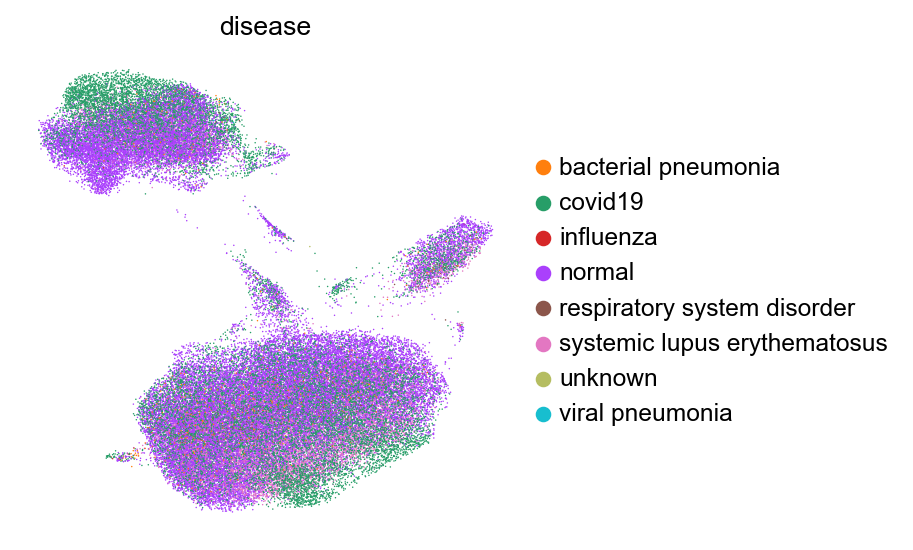

In [23]:
for color in colors:
    sc.pl.umap(adata_dc, color=color)